# Phân tích hiệu quả chiến dịch quảng cáo đa nền tảng – Shopee Sale 5.5

**Nhóm đề tài:** Marketing Analytics
**Dữ liệu:** 1.000 dòng chiến dịch quảng cáo (28/04/2024 – 10/05/2024) trên Facebook, TikTok, Google, Instagram, Shopee Ads.

**Câu hỏi nghiên cứu**
1. Nền tảng nào mang lại hiệu quả cao nhất (ROAS cao, CPA thấp)?
2. Loại nhóm quảng cáo (ad set) nào hiệu quả nhất / kém nhất?
3. Hiệu quả thay đổi thế nào theo thời gian, quanh ngày sale 5/5?
4. Nên phân bổ lại ngân sách như thế nào?

**Quy trình:** Khám phá dữ liệu → Làm sạch → Tính chỉ số marketing → Phân tích → Trực quan hóa → Kết luận & đề xuất

## 0. Cài đặt thư viện và cấu hình

In [1]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams['figure.dpi'] = 110

FILE_PATH = '_Huydata__shopee_sale_5_5_cleandata.xlsx'   # đặt file Excel cùng thư mục với notebook
os.makedirs('charts', exist_ok=True)                       # thư mục lưu biểu đồ

## 1. Đọc dữ liệu và khám phá ban đầu

In [ ]:
# Đọc tất cả cột dưới dạng chuỗi (str) để không mất thông tin các giá trị "bẩn" như '1,035', '1601$', '1O0'
raw = pd.read_excel("D:/DaiHoc/N3_HK1/PTDL/BTL/[Huydata] shopee_sale_5_5_cleandata.xlsx", dtype=str)
print('Kích thước:', raw.shape)
raw.head(10)

FileNotFoundError: [Errno 2] No such file or directory: '_Huydata__shopee_sale_5_5_cleandata.xlsx'

In [ ]:
# Số giá trị thiếu và số giá trị khác nhau trong mỗi cột
summary = pd.DataFrame({
    'so_gia_tri_thieu': raw.isna().sum(),
    'ty_le_thieu_%': raw.isna().mean() * 100,
    'so_gia_tri_khac_nhau': raw.nunique(),
})
summary

,so_gia_tri_thieu,ty_le_thieu_%,so_gia_tri_khac_nhau
campaign_id,0,0.00,1000
campaign_name,0,0.00,5
platform,0,0.00,30
ad_set,0,0.00,24
spend,70,7.00,717
clicks,50,5.00,669
impressions,35,3.50,925
conversions,54,5.40,140
revenue,45,4.50,919
date,0,0.00,97


## 2. Kiểm tra chất lượng dữ liệu (Data Quality Audit)

File có tên "cleandata" nhưng thực tế dữ liệu còn rất bẩn. Các nhóm lỗi cần xử lý:

In [ ]:
# Lỗi 1: tên nền tảng viết không thống nhất
print('Số cách viết tên nền tảng:', raw['platform'].nunique())
print(sorted(raw['platform'].unique()))
print()
# Lỗi 2: tên chiến dịch bị tách do khác hoa/thường
print(raw['campaign_name'].value_counts())

Số cách viết tên nền tảng: 30
['FACEBOOK', 'FB', 'FaceBook', 'Facebook Ads', 'GOOGLE', 'Google', 'Google Ads', 'IG', 'Instagram', 'Instagram Ads', 'SP Ads', 'SP ads', 'Shopee', 'Shopee Ads', 'TIKTOK', 'TT Ads', 'Tik Tok', 'TikTok', 'facebook', 'facebook_ads', 'fb', 'gg', 'google', 'google ads', 'ig', 'insta', 'instagram', 'shopee ads', 'tiktok', 'tiktok ads']

campaign_name
Shopee Sale 5.5          432
Shopee Mega Sale 5.5     151
shopee sale 5.5          144
Super Flash sale 5.5     138
Shopee 5.5 Flash Sale    135
Name: count, dtype: int64


In [ ]:
# Lỗi 3: các cột số chứa ký tự lạ (k, usd, $, đ, dấu phẩy, chữ O thay số 0, số viết bằng chữ...)
num_cols = ['spend', 'clicks', 'impressions', 'revenue']
rows = []
for c in num_cols:
    s = raw[c].dropna()
    bad = s[~s.str.fullmatch(r'\d+(\.\d+)?')]
    rows.append({'cot': c, 'so_dong_khong_phai_so_sach': len(bad), 'vi_du': list(bad.unique()[:8])})
pd.DataFrame(rows)

,cot,so_dong_khong_phai_so_sach,vi_du
0,spend,181,"[1,035, 1601$, 1.1k, 1,636, 1726đ, 2303$, 1.0k..."
1,clicks,40,"[1O0, one hundred, ten, 1O79, 14O1, 8O5, 1O18,..."
2,impressions,19,"[16,786, ten thousand, 23,016, 10,156, 7,477, ..."
3,revenue,68,"[4,265, 5,399, 3846$, 2668$, 4181$, 4776$, 2,2..."


In [ ]:
# Lỗi 4: ngày tháng có nhiều định dạng khác nhau
print('Số chuỗi ngày khác nhau:', raw['date'].nunique())
print(raw['date'].sample(12, random_state=1).tolist())

Số chuỗi ngày khác nhau: 97
['May 7 2024', '5-May-2024', '2024-05-03', '2024/04/30', '2024/05/03', '00/05/2024', '2024-05-10', '10-May-2024', '2024/05/03', '2024/04/28', 'Apr 28 2024', '07/05/2024']


## 3. Làm sạch dữ liệu (Data Cleaning)

Các quy tắc xử lý, ghi rõ để có thể giải thích khi thầy hỏi:

| Vấn đề | Cách xử lý |
|---|---|
| Tên nền tảng lộn xộn (30 cách viết) | Gom về 5 nền tảng chuẩn bằng bảng ánh xạ |
| Tên chiến dịch khác hoa/thường | Chuẩn hóa chữ hoa/thường |
| Số có ký tự lạ (`1,035`, `1601$`, `850usd`, `1726đ`, `1.2k`, `1 210`, `1029,00`, `1O0`) | Viết hàm `parse_num` để chuyển về số |
| Số viết bằng chữ (`ten thousand`, `two thousand`...) | Chuyển bằng từ điển |
| Chi phí âm | Coi là lỗi dấu, lấy giá trị tuyệt đối |
| Chi phí = 0 | Coi là thiếu dữ liệu (đã chạy quảng cáo thì phải có chi phí) → NaN |
| Clicks > Impressions (CTR > 100%, vô lý) | Impressions bất thường → NaN |
| Conversions > Clicks hoặc quá lớn so với phân bố (outlier) | Coi là lỗi nhập liệu → NaN |
| Ngày nhiều định dạng, một số ngày không tồn tại | Chuẩn hóa về `datetime`; ngày sai/ngoài khoảng 28/04–10/05 → NaT |
| Giá trị thiếu | **Không điền (impute)**: mỗi chỉ số chỉ tính trên những dòng có đủ dữ liệu cần thiết, tránh làm sai lệch ROAS/CPA |

In [ ]:
df = raw.copy()

# ---------- 3.1 Chuẩn hóa tên nền tảng ----------
PLATFORM_MAP = {
    'facebook': 'Facebook', 'facebookads': 'Facebook', 'fb': 'Facebook',
    'tiktok': 'TikTok', 'tiktokads': 'TikTok', 'ttads': 'TikTok',
    'google': 'Google', 'googleads': 'Google', 'gg': 'Google',
    'instagram': 'Instagram', 'instagramads': 'Instagram', 'ig': 'Instagram', 'insta': 'Instagram',
    'shopee': 'Shopee Ads', 'shopeeads': 'Shopee Ads', 'spads': 'Shopee Ads',
}
key = df['platform'].str.lower().str.replace(r'[^a-z]', '', regex=True)
df['platform'] = key.map(PLATFORM_MAP)
print('Nền tảng sau chuẩn hóa:', df['platform'].value_counts().to_dict())
print('Không ánh xạ được:', df['platform'].isna().sum())

# ---------- 3.2 Chuẩn hóa tên chiến dịch ----------
df['campaign_name'] = df['campaign_name'].str.strip().str.title()   # 'shopee sale 5.5' -> 'Shopee Sale 5.5'
print(df['campaign_name'].value_counts().to_dict())

Nền tảng sau chuẩn hóa: {'Facebook': 285, 'TikTok': 243, 'Google': 183, 'Shopee Ads': 146, 'Instagram': 143}
Không ánh xạ được: 0
{'Shopee Sale 5.5': 576, 'Shopee Mega Sale 5.5': 151, 'Super Flash Sale 5.5': 138, 'Shopee 5.5 Flash Sale': 135}


In [ ]:
# ---------- 3.3 Hàm chuyển chuỗi "bẩn" thành số ----------
WORDS = {'ten': 10, 'one hundred': 100, 'two thousand': 2000, 'ten thousand': 10000}

def parse_num(x):
    """Chuyển các dạng '1,035' '1601$' '850usd' '1726đ' '1.2k' '1,8k' '1 210' '1029,00' '1O0' 'ten thousand' về số float."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in WORDS:                                   # số viết bằng chữ
        return float(WORDS[s])
    s = re.sub(r'(usd|\$|đ|vnd)', '', s).strip()    # bỏ ký hiệu tiền tệ
    s = re.sub(r'(?<=\d)o|o(?=\d)', '0', s)          # chữ O thay cho số 0
    s = s.replace(' ', '')                           # dấu cách ngăn hàng nghìn
    mult = 1
    if s.endswith('k'):                              # đuôi k = nghìn, vd '1,8k' = 1800
        mult = 1000
        s = s[:-1].replace(',', '.')
    elif re.fullmatch(r'-?\d+,\d{2}', s):            # '1029,00' = số thập phân kiểu châu Âu
        s = s.replace(',', '.')
    else:                                            # '1,035' = dấu phẩy hàng nghìn
        s = s.replace(',', '')
    try:
        return float(s) * mult
    except ValueError:
        return np.nan

for c in ['spend', 'clicks', 'impressions', 'revenue']:
    df[c] = df[c].map(parse_num)
df['conversions'] = pd.to_numeric(df['conversions'])

# kiểm tra: còn giá trị nào có dữ liệu gốc nhưng không chuyển được?
for c in ['spend', 'clicks', 'impressions', 'revenue']:
    print(c, '- không chuyển được:', (raw[c].notna() & df[c].isna()).sum())

spend - không chuyển được: 0
clicks - không chuyển được: 0
impressions - không chuyển được: 0
revenue - không chuyển được: 0


In [ ]:
# ---------- 3.4 Xử lý giá trị bất thường ----------
log = {}   # ghi lại số dòng bị ảnh hưởng ở mỗi bước

# (a) chi phí âm -> lấy trị tuyệt đối
log['spend âm (đổi dấu)'] = int((df['spend'] < 0).sum())
df['spend'] = df['spend'].abs()

# (b) chi phí = 0 -> thiếu dữ liệu
log['spend = 0 (chuyển thành NaN)'] = int((df['spend'] == 0).sum())
df.loc[df['spend'] == 0, 'spend'] = np.nan

# (c) clicks > impressions -> impressions bất thường
mask = df['clicks'] > df['impressions']
log['clicks > impressions (impressions -> NaN)'] = int(mask.sum())
df.loc[mask, 'impressions'] = np.nan

# (d) conversions > clicks, hoặc vượt hàng rào ngoại lai (Q3 + 3*IQR)
q1, q3 = df['conversions'].quantile([.25, .75])
upper = q3 + 3 * (q3 - q1)
mask = (df['conversions'] > df['clicks']) | (df['conversions'] > upper)
log[f'conversions > clicks hoặc > {upper:.0f} (-> NaN)'] = int(mask.sum())
df.loc[mask, 'conversions'] = np.nan

pd.Series(log, name='so_dong').to_frame()

,so_dong
spend âm (đổi dấu),17
spend = 0 (chuyển thành NaN),12
clicks > impressions (impressions -> NaN),23
conversions > clicks hoặc > 187 (-> NaN),26


In [ ]:
# ---------- 3.5 Chuẩn hóa ngày tháng ----------
DATE_PATTERNS = [
    (r'\d{4}-\d{2}-\d{2}',        '%Y-%m-%d'),   # 2024-05-06
    (r'\d{4}/\d{2}/\d{2}',        '%Y/%m/%d'),   # 2024/05/06
    (r'\d{4}\.\d{2}\.\d{2}',      '%Y.%m.%d'),   # 2024.05.06
    (r'\d{1,2}-[A-Za-z]{3}-\d{4}', '%d-%b-%Y'),   # 6-May-2024
    (r'[A-Za-z]{3} \d{1,2} \d{4}',  '%b %d %Y'),   # May 6 2024
    (r'\d{2}/\d{2}/\d{4}',        '%d/%m/%Y'),   # 06/05/2024  (ngày/tháng)
    (r'\d{2}-\d{2}-\d{4}',        '%m-%d-%Y'),   # 05-06-2024  (tháng-ngày; vì dữ liệu chỉ có 04-xx và 05-xx)
]

def parse_date(x):
    s = str(x).strip()
    for pattern, fmt in DATE_PATTERNS:
        if re.fullmatch(pattern, s):
            return pd.to_datetime(s, format=fmt, errors='coerce')
    return pd.NaT

df['date'] = df['date'].map(parse_date)

# ngày nằm ngoài khoảng của chiến dịch -> coi là sai
START, END = pd.Timestamp('2024-04-28'), pd.Timestamp('2024-05-10')
df.loc[(df['date'] < START) | (df['date'] > END), 'date'] = pd.NaT
print('Số dòng có ngày không hợp lệ (00/05, 32/05, 35/05, tháng 13...):', df['date'].isna().sum())
print('Khoảng ngày:', df['date'].min().date(), '->', df['date'].max().date())

Số dòng có ngày không hợp lệ (00/05, 32/05, 35/05, tháng 13...): 28
Khoảng ngày: 2024-04-28 -> 2024-05-10


## 4. Tạo các chỉ số marketing

| Chỉ số | Công thức | Ý nghĩa |
|---|---|---|
| **CTR** | clicks / impressions | Tỉ lệ người thấy quảng cáo và bấm vào |
| **CPC** | spend / clicks | Chi phí cho mỗi lượt click |
| **CVR** | conversions / clicks | Tỉ lệ click chuyển thành đơn |
| **CPA** | spend / conversions | Chi phí để có một đơn |
| **ROAS** | revenue / spend | Doanh thu thu về trên mỗi 1 đồng chi quảng cáo |

Mỗi dòng chỉ tính chỉ số khi **đủ cả tử số và mẫu số**; dòng thiếu thì để NaN.

In [ ]:
df['CTR']  = df['clicks'] / df['impressions']
df['CPC']  = df['spend'] / df['clicks']
df['CVR']  = df['conversions'] / df['clicks']
df['CPA']  = df['spend'] / df['conversions']
df['ROAS'] = df['revenue'] / df['spend']

# Phân loại nhóm quảng cáo (ad set) theo mục tiêu để dễ so sánh
def ad_set_group(a):
    if 'Retargeting' in a:                                   return 'Retargeting'
    if a.startswith('Lookalike') or a == 'Prospecting':      return 'Lookalike / Prospecting'
    if a.startswith('Search') or a == 'Keyword Auto':        return 'Search'
    if a in ['Shopping', 'PMAX', 'Catalog Sales', 'Shop Ads', 'Product Boost', 'GMV Max']:
                                                             return 'Shopping / Catalog'
    if a in ['Video View', 'Stories', 'Reels', 'Live Ads', 'Discovery']:
                                                             return 'Video / Content'
    if a in ['Influencer', 'Creator Post']:                  return 'Influencer / Creator'
    return 'Khác'
df['ad_set_group'] = df['ad_set'].map(ad_set_group)

df['day'] = df['date'].dt.date
print(df['ad_set_group'].value_counts().to_dict())
df[['campaign_id','platform','ad_set','spend','revenue','CTR','CVR','CPA','ROAS']].head()

{'Shopping / Catalog': 242, 'Video / Content': 229, 'Lookalike / Prospecting': 193, 'Search': 167, 'Retargeting': 117, 'Influencer / Creator': 52}


,campaign_id,platform,ad_set,spend,revenue,CTR,CVR,CPA,ROAS
0,C001,Facebook,Lookalike 5%,NaN,"8,383.00",0.07,0.07,NaN,NaN
1,C002,Facebook,Retargeting,"1,035.00","4,265.00",0.05,0.04,24.64,4.12
2,C003,TikTok,Shop Ads,"1,580.00","6,396.00",0.06,0.05,34.35,4.05
3,C004,Facebook,Lookalike 5%,NaN,"6,052.00",0.07,0.04,NaN,NaN
4,C005,Google,Shopping,"1,272.00","5,387.00",0.06,0.08,31.80,4.24


### 4.2 Tạo biến mới (Feature Engineering)

Dữ liệu này là dữ liệu **chiến dịch quảng cáo** (không có từng đơn hàng, giờ mua, voucher), nên các biến mới được tạo từ những cột sẵn có:

| Biến mới | Công thức | Ý nghĩa |
|---|---|---|
| `AOV` | revenue / conversions | Giá trị trung bình mỗi đơn (tương đương "tổng tiền đơn hàng") |
| `day_of_week`, `is_weekend` | từ `date` | Thứ trong tuần, cuối tuần hay ngày thường |
| `days_from_start` | date − 28/04 | Khoảng cách ngày kể từ khi bắt đầu chiến dịch |
| `phase` | so với ngày 5/5 | Trước sale / Ngày sale / Sau sale |
| `spend_tier` | chia 3 mức theo spend | Ngân sách Thấp / Trung bình / Cao |

In [ ]:
VN_DAY = {'Monday': 'Thứ 2', 'Tuesday': 'Thứ 3', 'Wednesday': 'Thứ 4', 'Thursday': 'Thứ 5',
          'Friday': 'Thứ 6', 'Saturday': 'Thứ 7', 'Sunday': 'Chủ nhật'}

df['AOV'] = df['revenue'] / df['conversions']
df['day_of_week'] = df['date'].dt.day_name().map(VN_DAY)
df['day_type'] = np.where(df['date'].dt.dayofweek >= 5, 'Cuối tuần', 'Ngày thường')
df.loc[df['date'].isna(), 'day_type'] = np.nan   # dòng thiếu ngày thì không phân loại
df['days_from_start'] = (df['date'] - START).dt.days

def phase(d):
    if pd.isna(d): return np.nan
    if d < pd.Timestamp('2024-05-05'):  return '1. Trước sale (28/4–4/5)'
    if d == pd.Timestamp('2024-05-05'): return '2. Ngày sale (5/5)'
    return '3. Sau sale (6/5–10/5)'
df['phase'] = df['date'].map(phase)

df['spend_tier'] = pd.qcut(df['spend'], 3, labels=['Thấp', 'Trung bình', 'Cao'])
df[['campaign_id', 'date', 'day_of_week', 'day_type', 'phase', 'spend', 'spend_tier', 'AOV']].head()

,campaign_id,date,day_of_week,day_type,phase,spend,spend_tier,AOV
0,C001,2024-05-06,Thứ 2,Ngày thường,3. Sau sale (6/5–10/5),NaN,NaN,121.49
1,C002,2024-05-02,Thứ 5,Ngày thường,1. Trước sale (28/4–4/5),"1,035.00",Trung bình,101.55
2,C003,2024-05-10,Thứ 6,Ngày thường,3. Sau sale (6/5–10/5),"1,580.00",Cao,139.04
3,C004,2024-05-08,Thứ 4,Ngày thường,3. Sau sale (6/5–10/5),NaN,NaN,114.19
4,C005,2024-05-09,Thứ 5,Ngày thường,3. Sau sale (6/5–10/5),"1,272.00",Trung bình,134.68


In [ ]:
# Lưu dữ liệu đã làm sạch
df.drop(columns=['day']).to_csv('shopee_5_5_cleaned.csv', index=False, encoding='utf-8-sig')

# Báo cáo mức độ đầy đủ sau làm sạch
completeness = pd.DataFrame({'so_dong_thieu': df.isna().sum(), 'ty_le_thieu_%': df.isna().mean()*100})
completeness.loc[['platform','spend','clicks','impressions','conversions','revenue','date']]

,so_dong_thieu,ty_le_thieu_%
platform,0,0.00
spend,82,8.20
clicks,50,5.00
impressions,58,5.80
conversions,80,8.00
revenue,45,4.50
date,28,2.80


## 5. Phân tích

Hàm `summarize` tính chỉ số **ở mức tổng hợp** theo từng nhóm (tổng tử / tổng mẫu), chỉ dùng những dòng đủ dữ liệu cho từng chỉ số. Cách này chính xác hơn việc lấy trung bình của các tỉ lệ từng dòng.

In [ ]:
def ratio(g, num, den):
    """Tổng num / Tổng den, chỉ trên các dòng có đủ cả hai giá trị."""
    m = g[num].notna() & g[den].notna()
    return g.loc[m, num].sum() / g.loc[m, den].sum() if m.any() and g.loc[m, den].sum() > 0 else np.nan

def summarize(data, by):
    rows = []
    for k, g in data.groupby(by, observed=True):
        rows.append({
            by: k,
            'so_chien_dich': len(g),
            'tong_spend': g['spend'].sum(),
            'tong_revenue': g['revenue'].sum(),
            'CTR_%': ratio(g, 'clicks', 'impressions') * 100,
            'CPC':   ratio(g, 'spend', 'clicks'),
            'CVR_%': ratio(g, 'conversions', 'clicks') * 100,
            'CPA':   ratio(g, 'spend', 'conversions'),
            'AOV':   ratio(g, 'revenue', 'conversions'),
            'ROAS':  ratio(g, 'revenue', 'spend'),
        })
    return pd.DataFrame(rows).set_index(by)

overall = {
    'Tổng chi phí (spend)': df['spend'].sum(),
    'Tổng doanh thu (revenue)': df['revenue'].sum(),
    'CTR chung %': ratio(df, 'clicks', 'impressions') * 100,
    'CVR chung %': ratio(df, 'conversions', 'clicks') * 100,
    'CPA chung': ratio(df, 'spend', 'conversions'),
    'ROAS chung': ratio(df, 'revenue', 'spend'),
}
pd.Series(overall, name='Toàn chiến dịch').to_frame()

,Toàn chiến dịch
Tổng chi phí (spend),"1,204,095.00"
Tổng doanh thu (revenue),"6,266,365.00"
CTR chung %,6.00
CVR chung %,5.62
CPA chung,23.72
ROAS chung,4.99


### 5.1 Hiệu quả theo nền tảng

In [ ]:
by_platform = summarize(df, 'platform').sort_values('ROAS', ascending=False)
by_platform

,so_chien_dich,tong_spend,tong_revenue,CTR_%,CPC,CVR_%,CPA,AOV,ROAS
platform,,,,,,,,,
Shopee Ads,146,"101,653.00","601,805.00",5.42,0.85,4.63,18.63,109.32,5.85
Facebook,285,"289,586.00","1,720,168.00",6.22,1.09,5.40,20.02,114.11,5.73
Instagram,143,"120,301.00","690,188.00",5.34,1.03,4.44,23.15,125.19,5.50
Google,183,"290,444.00","1,384,002.00",5.55,1.87,7.00,26.03,125.20,4.76
TikTok,243,"402,111.00","1,870,202.00",6.81,1.68,6.02,27.91,119.21,4.25


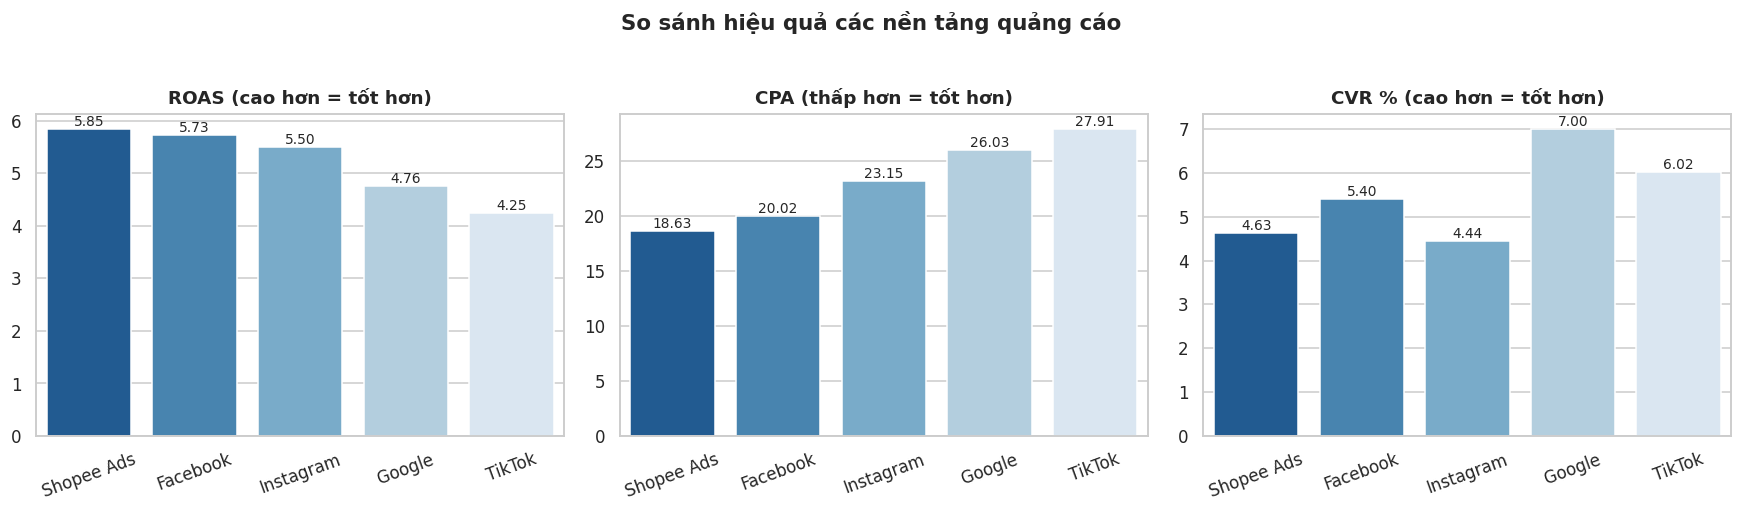

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
order = by_platform.index
palette = sns.color_palette('Blues_r', len(order))

for ax, col, title in zip(axes, ['ROAS', 'CPA', 'CVR_%'],
                          ['ROAS (cao hơn = tốt hơn)', 'CPA (thấp hơn = tốt hơn)', 'CVR % (cao hơn = tốt hơn)']):
    sns.barplot(x=by_platform.index, y=by_platform[col], hue=by_platform.index, order=order, palette=palette, legend=False, ax=ax)
    ax.set_title(title, fontweight='bold'); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=20)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.suptitle('So sánh hiệu quả các nền tảng quảng cáo', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('charts/01_platform_performance.png', bbox_inches='tight')
plt.show()

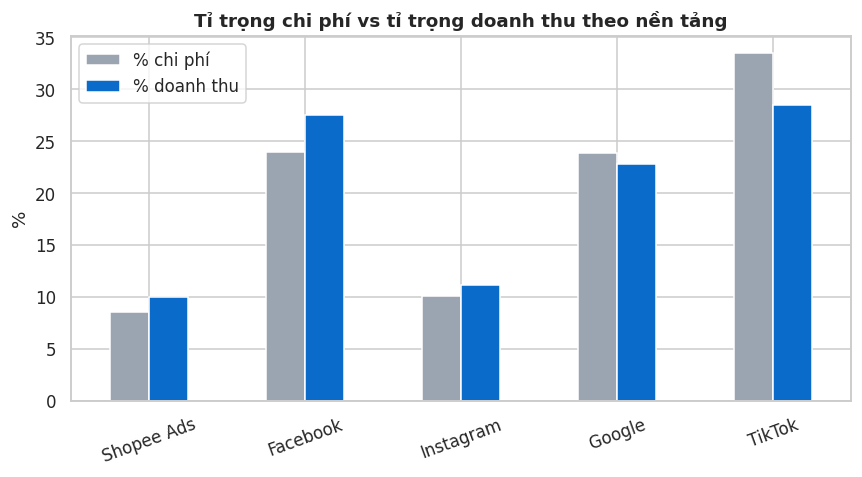

,ty_trong_spend_%,ty_trong_revenue_%,chenh_lech
platform,,,
Shopee Ads,8.53,9.99,1.47
Facebook,23.99,27.54,3.55
Instagram,10.12,11.16,1.04
Google,23.89,22.81,-1.09
TikTok,33.47,28.50,-4.97


In [ ]:
# Tỉ trọng chi phí so với tỉ trọng doanh thu: nền tảng nào "đóng góp doanh thu nhiều hơn phần tiền bỏ ra"?
# (chỉ dùng các dòng có đủ cả spend và revenue để hai tỉ trọng so sánh được với nhau)
both = df.dropna(subset=['spend', 'revenue']).groupby('platform')[['spend', 'revenue']].sum().loc[by_platform.index]
share = pd.DataFrame({
    'ty_trong_spend_%': both['spend'] / both['spend'].sum() * 100,
    'ty_trong_revenue_%': both['revenue'] / both['revenue'].sum() * 100,
})
share['chenh_lech'] = share['ty_trong_revenue_%'] - share['ty_trong_spend_%']

ax = share[['ty_trong_spend_%', 'ty_trong_revenue_%']].plot(kind='bar', figsize=(8, 4.5), color=['#9aa5b1', '#0b6bcb'])
ax.set_title('Tỉ trọng chi phí vs tỉ trọng doanh thu theo nền tảng', fontweight='bold')
ax.set_ylabel('%'); ax.set_xlabel(''); plt.xticks(rotation=20)
ax.legend(['% chi phí', '% doanh thu'])
plt.tight_layout(); plt.savefig('charts/02_spend_vs_revenue_share.png', bbox_inches='tight'); plt.show()
share

### Kiểm định: chênh lệch ROAS giữa các nhóm có thật hay chỉ do ngẫu nhiên?

Dùng kiểm định **Kruskal-Wallis** (phi tham số, phù hợp vì ROAS lệch phải và có ngoại lai). Giả thuyết H0: ROAS của các nhóm không khác nhau. Nếu p < 0.05 thì bác bỏ H0.

In [ ]:
from scipy import stats

def kruskal_test(col):
    groups = [g['ROAS'].dropna() for _, g in df.groupby(col)]
    stat, p = stats.kruskal(*groups)
    return stat, p

for col in ['platform', 'ad_set_group']:
    stat, p = kruskal_test(col)
    print(f'ROAS theo {col:13s}: H = {stat:6.2f}, p = {p:.4g} ->', 'KHÁC BIỆT có ý nghĩa thống kê' if p < 0.05 else 'chưa đủ bằng chứng khác biệt')

ROAS theo platform     : H =  41.58, p = 2.042e-08 -> KHÁC BIỆT có ý nghĩa thống kê
ROAS theo ad_set_group : H =   7.56, p = 0.182 -> chưa đủ bằng chứng khác biệt


### 5.2 Hiệu quả theo nhóm quảng cáo (ad set)

In [ ]:
by_group = summarize(df, 'ad_set_group').sort_values('ROAS', ascending=False)
by_group

,so_chien_dich,tong_spend,tong_revenue,CTR_%,CPC,CVR_%,CPA,AOV,ROAS
ad_set_group,,,,,,,,,
Lookalike / Prospecting,193,"197,862.00","1,179,862.00",6.26,1.08,5.34,20.19,115.18,5.79
Search,167,"184,482.00","934,684.00",5.61,1.36,5.79,22.69,118.72,5.04
Influencer / Creator,52,"45,800.00","226,316.00",5.15,1.14,4.42,25.07,123.21,4.99
Shopping / Catalog,242,"332,700.00","1,707,138.00",6.20,1.47,6.10,24.28,118.32,4.83
Retargeting,117,"142,214.00","742,928.00",6.13,1.35,5.36,25.29,117.08,4.75
Video / Content,229,"301,037.00","1,475,437.00",5.97,1.45,5.58,25.82,121.81,4.73


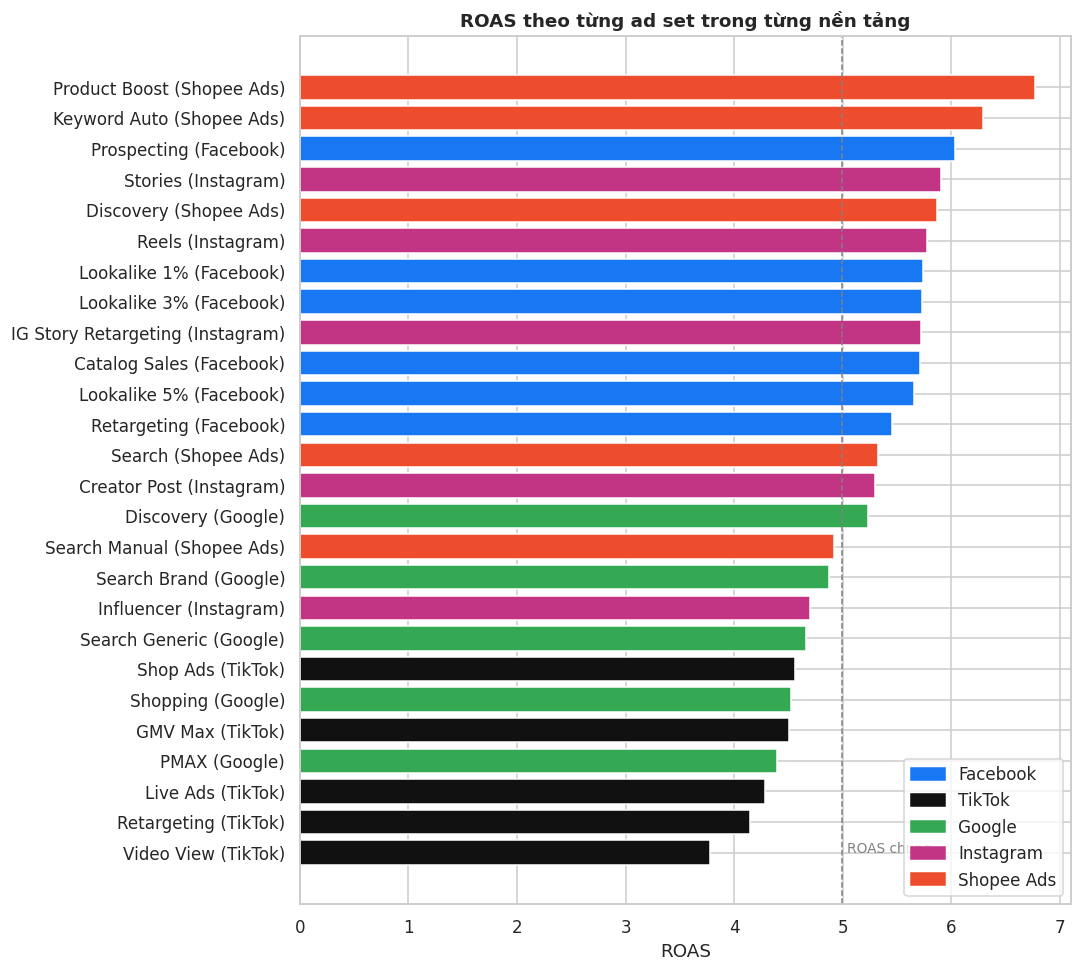

Top 5 ad set có ROAS cao nhất:


,so_chien_dich,tong_spend,CPA,CVR_%,ROAS
adset_platform,,,,,
Product Boost (Shopee Ads),28,"20,357.00",16.34,4.89,6.77
Keyword Auto (Shopee Ads),30,"20,886.00",16.43,4.57,6.29
Prospecting (Facebook),51,"49,787.00",19.10,5.39,6.03
Stories (Instagram),35,"27,891.00",22.82,4.31,5.91
Discovery (Shopee Ads),28,"18,268.00",19.72,4.54,5.87


Top 5 ad set có ROAS thấp nhất:


,so_chien_dich,tong_spend,CPA,CVR_%,ROAS
adset_platform,,,,,
GMV Max (TikTok),57,"95,389.00",26.74,6.30,4.50
PMAX (Google),37,"55,451.00",28.28,6.79,4.39
Live Ads (TikTok),54,"86,617.00",26.47,5.94,4.28
Retargeting (TikTok),49,"80,865.00",30.34,5.67,4.14
Video View (TikTok),45,"79,650.00",31.60,6.01,3.78


In [ ]:
# Lưu ý: một số tên ad set (Retargeting, Discovery) xuất hiện ở 2 nền tảng khác nhau -> phân tích theo cặp (ad set, nền tảng)
df['adset_platform'] = df['ad_set'] + ' (' + df['platform'] + ')'
by_adset = summarize(df, 'adset_platform').sort_values('ROAS', ascending=False)
by_adset['platform'] = by_adset.index.str.rsplit('(', n=1).str[-1].str.rstrip(')')

COLORS = {'Facebook': '#1877f2', 'TikTok': '#111111', 'Google': '#34a853', 'Instagram': '#c13584', 'Shopee Ads': '#ee4d2d'}
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(by_adset.index[::-1], by_adset['ROAS'][::-1], color=by_adset['platform'].map(COLORS)[::-1])
ax.axvline(ratio(df, 'revenue', 'spend'), color='gray', ls='--', lw=1)
ax.text(ratio(df, 'revenue', 'spend') + 0.05, 0, 'ROAS chung', color='gray', fontsize=9)
ax.set_title('ROAS theo từng ad set trong từng nền tảng', fontweight='bold')
ax.set_xlabel('ROAS')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=p) for p, c in COLORS.items()], loc='lower right')
plt.tight_layout(); plt.savefig('charts/03_roas_by_adset.png', bbox_inches='tight'); plt.show()

cols = ['so_chien_dich', 'tong_spend', 'CPA', 'CVR_%', 'ROAS']
print('Top 5 ad set có ROAS cao nhất:');  display(by_adset[cols].head(5))
print('Top 5 ad set có ROAS thấp nhất:'); display(by_adset[cols].tail(5))

### 5.3 Diễn biến theo thời gian

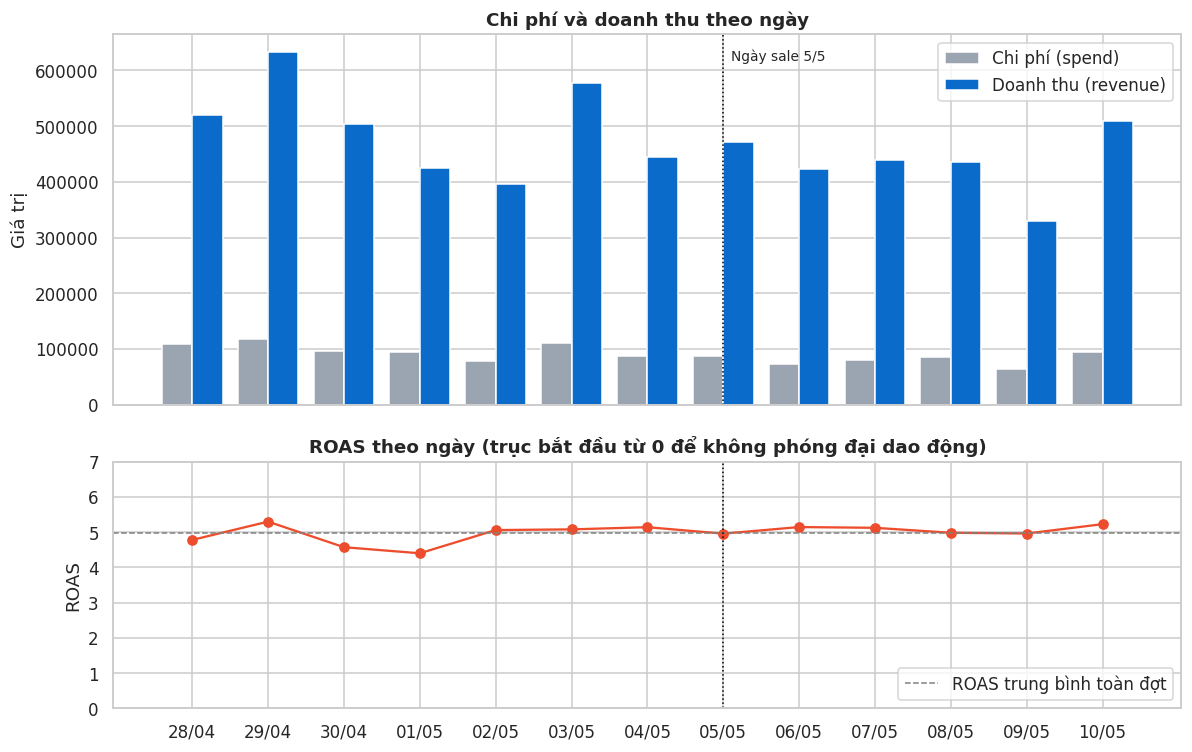

,so_chien_dich,tong_spend,tong_revenue,CVR_%,CPA,ROAS
day,,,,,,
2024-04-28,84,"108,147.00","519,150.00",5.63,25.02,4.78
2024-04-29,89,"117,920.00","633,233.00",5.94,22.35,5.30
2024-04-30,81,"96,447.00","504,018.00",5.69,26.17,4.57
2024-05-01,72,"95,228.00","423,930.00",5.69,27.41,4.40
2024-05-02,62,"78,049.00","395,598.00",5.89,23.24,5.06
2024-05-03,88,"110,056.00","576,784.00",5.55,23.43,5.08
2024-05-04,72,"86,665.00","443,868.00",5.49,22.49,5.14
2024-05-05,78,"86,470.00","471,034.00",5.70,23.58,4.96
2024-05-06,65,"72,530.00","422,296.00",5.62,22.04,5.14


In [ ]:
daily = summarize(df.dropna(subset=['date']), 'day')
daily.index = pd.to_datetime(daily.index)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
x = np.arange(len(daily)); w = 0.4
ax1.bar(x - w/2, daily['tong_spend'], w, color='#9aa5b1', label='Chi phí (spend)')
ax1.bar(x + w/2, daily['tong_revenue'], w, color='#0b6bcb', label='Doanh thu (revenue)')
ax1.set_ylabel('Giá trị'); ax1.legend(loc='upper right'); ax1.set_title('Chi phí và doanh thu theo ngày', fontweight='bold')

ax2.plot(x, daily['ROAS'], color='#ee4d2d', marker='o')
ax2.axhline(ratio(df, 'revenue', 'spend'), color='gray', ls='--', lw=1, label='ROAS trung bình toàn đợt')
ax2.set_ylim(0, 7); ax2.set_ylabel('ROAS'); ax2.legend(loc='lower right')
ax2.set_title('ROAS theo ngày (trục bắt đầu từ 0 để không phóng đại dao động)', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels([d.strftime('%d/%m') for d in daily.index])

i_sale = list(daily.index).index(pd.Timestamp('2024-05-05'))
for ax in (ax1, ax2):
    ax.axvline(i_sale, color='black', ls=':', lw=1)
ax1.text(i_sale + 0.1, ax1.get_ylim()[1] * 0.93, 'Ngày sale 5/5', fontsize=9)
plt.tight_layout()
plt.savefig('charts/04_daily_trend.png', bbox_inches='tight'); plt.show()
daily[['so_chien_dich', 'tong_spend', 'tong_revenue', 'CVR_%', 'CPA', 'ROAS']]

In [ ]:
# So sánh trước / ngày sale / sau ngày sale (biến `phase` đã tạo ở phần 4.2)
by_phase = summarize(df.dropna(subset=['phase']), 'phase')
display(by_phase)

# Cuối tuần và ngày thường (lưu ý: 28/4, 4/5, 5/5 là cuối tuần)
summarize(df.dropna(subset=['day_type']), 'day_type')

,so_chien_dich,tong_spend,tong_revenue,CTR_%,CPC,CVR_%,CPA,AOV,ROAS
phase,,,,,,,,,
1. Trước sale (28/4–4/5),548,"692,512.00","3,496,581.00",6.06,1.38,5.70,24.14,118.57,4.92
2. Ngày sale (5/5),78,"86,470.00","471,034.00",5.92,1.31,5.70,23.58,118.14,4.96
3. Sau sale (6/5–10/5),346,"396,341.00","2,135,479.00",5.92,1.30,5.51,23.12,118.94,5.10


,so_chien_dich,tong_spend,tong_revenue,CTR_%,CPC,CVR_%,CPA,AOV,ROAS
day_type,,,,,,,,,
Cuối tuần,234,"281,282.00","1,434,052.00",6.10,1.31,5.61,23.77,117.34,4.94
Ngày thường,738,"894,041.00","4,669,042.00",5.97,1.35,5.64,23.75,119.09,4.99


### 5.4 Nền tảng × Ad set (heatmap ROAS) và so sánh tên chiến dịch

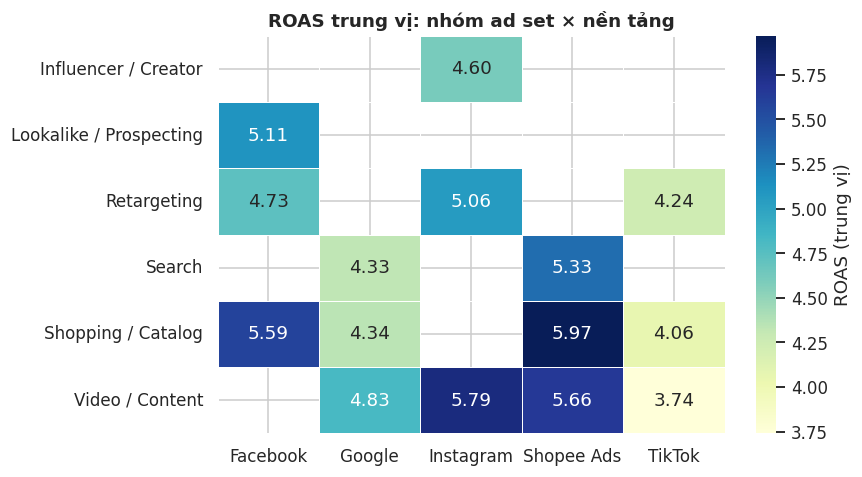

In [ ]:
pivot = df.pivot_table(index='ad_set_group', columns='platform', values='ROAS', aggfunc='median')
plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', linewidths=.5, cbar_kws={'label': 'ROAS (trung vị)'})
plt.title('ROAS trung vị: nhóm ad set × nền tảng', fontweight='bold')
plt.ylabel(''); plt.xlabel('')
plt.tight_layout(); plt.savefig('charts/05_heatmap_group_platform.png', bbox_inches='tight'); plt.show()

In [ ]:
by_campaign = summarize(df, 'campaign_name').sort_values('ROAS', ascending=False)
by_campaign

,so_chien_dich,tong_spend,tong_revenue,CTR_%,CPC,CVR_%,CPA,AOV,ROAS
campaign_name,,,,,,,,,
Shopee 5.5 Flash Sale,135,"159,234.00","864,661.00",6.18,1.28,5.48,24.13,120.59,5.19
Shopee Mega Sale 5.5,151,"195,163.00","973,146.00",6.07,1.34,5.67,22.65,116.80,5.02
Super Flash Sale 5.5,138,"164,735.00","894,260.00",5.87,1.38,5.74,23.47,119.08,5.00
Shopee Sale 5.5,576,"684,963.00","3,534,298.00",5.97,1.35,5.61,24.00,118.55,4.93


### 5.5 Mối quan hệ giữa chi phí và hiệu quả

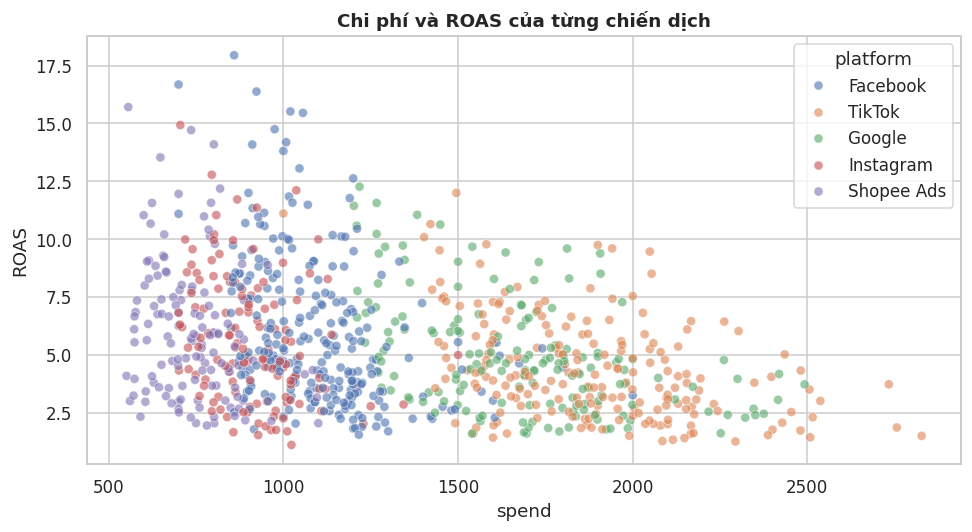

Hệ số tương quan Pearson (spend, ROAS): -0.35


In [ ]:
sub = df.dropna(subset=['spend', 'ROAS'])
plt.figure(figsize=(9, 5))
sns.scatterplot(data=sub, x='spend', y='ROAS', hue='platform', alpha=.6)
plt.title('Chi phí và ROAS của từng chiến dịch', fontweight='bold')
plt.tight_layout(); plt.savefig('charts/06_spend_vs_roas.png', bbox_inches='tight'); plt.show()
print('Hệ số tương quan Pearson (spend, ROAS):', round(sub['spend'].corr(sub['ROAS']), 3))

### 5.6 Mô phỏng nhanh: nếu chuyển một phần ngân sách TikTok sang Facebook và Shopee Ads

**Giả định (rất đơn giản, chỉ để minh họa):** ROAS của mỗi nền tảng giữ nguyên khi thay đổi ngân sách. Thực tế ROAS thường giảm khi tăng chi (xem biểu đồ 5.5) nên kết quả thật có thể thấp hơn.

In [ ]:
sp = both['spend']
roas_tt = by_platform.loc['TikTok', 'ROAS']
# ROAS bình quân gia quyền (theo tỉ trọng chi phí hiện tại) của Facebook + Shopee Ads
dest = ['Facebook', 'Shopee Ads']
roas_dest = (by_platform.loc[dest, 'ROAS'] * sp[dest]).sum() / sp[dest].sum()
base_revenue = both['revenue'].sum()

rows = []
for pct in [5, 10, 15, 20]:
    moved = sp['TikTok'] * pct / 100
    gain = moved * (roas_dest - roas_tt)
    rows.append({'chuyen_%_ngan_sach_TikTok': pct, 'so_tien_chuyen': moved,
                 'doanh_thu_tang_them': gain, 'tang_%_so_voi_tong_doanh_thu': gain / base_revenue * 100})
pd.DataFrame(rows).set_index('chuyen_%_ngan_sach_TikTok')

,so_tien_chuyen,doanh_thu_tang_them,tang_%_so_voi_tong_doanh_thu
chuyen_%_ngan_sach_TikTok,,,
5,"19,302.95","29,146.02",0.51
10,"38,605.90","58,292.03",1.01
15,"57,908.85","87,438.05",1.52
20,"77,211.80","116,584.07",2.03


## 6. Kết luận và đề xuất

*(Số liệu theo lần chạy hiện tại trên dữ liệu đã làm sạch.)*

### 6.1 Về dữ liệu
- File "cleandata" thực tế chứa nhiều lỗi: 30 cách viết cho 5 nền tảng, số lẫn ký tự (`k`, `usd`, `$`, `đ`, chữ `O`, số viết bằng chữ), chi phí âm hoặc bằng 0, clicks > impressions, conversions bất thường, 8 định dạng ngày và 28 ngày không hợp lệ.
- Sau làm sạch, tỉ lệ thiếu còn 4.5–8.2% mỗi cột. Không điền giá trị thiếu mà tính chỉ số trên các dòng đủ dữ liệu, để không làm lệch ROAS và CPA.

### 6.2 Các phát hiện chính
1. **Toàn chiến dịch:** ROAS ≈ 5.0 (mỗi 1 đồng chi quảng cáo thu khoảng 5 đồng doanh thu), CPA ≈ 23.7, CVR ≈ 5.6%.
2. **Nền tảng khác biệt rõ rệt (kiểm định Kruskal-Wallis, p < 0.001):**
   - Tốt nhất: **Shopee Ads** (ROAS 5.85, CPA 18.6) và **Facebook** (ROAS 5.73, CPA 20.0).
   - Kém nhất: **TikTok** (ROAS 4.25, CPA 27.9) và **Google** (ROAS 4.76, CPA 26.0).
3. **Ngân sách đang phân bổ chưa tối ưu:** TikTok chiếm ~33.5% chi phí nhưng chỉ đem lại ~28.5% doanh thu; Facebook chi ~24.0% nhưng đem lại ~27.5% doanh thu.
4. **Google có CVR cao nhất (7.0%)** nhưng CPC cũng cao nhất (1.87) nên ROAS vẫn thấp: lưu lượng đắt nhưng chuyển đổi tốt. TikTok có CTR cao nhất (6.8%) nhưng click không chuyển thành đơn đủ tốt.
5. **Ad set:** top gồm Product Boost (ROAS 6.77) và Keyword Auto (6.29) của Shopee Ads, Prospecting (6.03) của Facebook, Stories (5.91) của Instagram. Kém nhất là TikTok Video View (3.78) và Live Ads (4.28), Google PMAX (4.39).
6. **Loại ad set (nhóm) không tạo khác biệt có ý nghĩa thống kê (p ≈ 0.18):** hiệu quả phụ thuộc vào **nền tảng** nhiều hơn là kiểu nhắm mục tiêu.
7. **Thời gian:** ROAS khá ổn định (≈ 4.9–5.1) trước, trong và sau ngày 5/5; không thấy đỉnh hiệu quả vào đúng ngày sale. Chi phí giảm dần về cuối đợt (từ khoảng 108 nghìn ngày 28/4 xuống khoảng 64 nghìn ngày 9/5). Giá trị trung bình mỗi đơn (AOV ≈ 118) gần như không đổi trước, trong và sau sale; cuối tuần và ngày thường cũng không khác biệt (ROAS 4.94 so với 4.99).
8. **Chi phí càng lớn, ROAS càng thấp** (tương quan ≈ -0.35): dấu hiệu lợi suất giảm dần, nhưng chưa thể kết luận nhân quả.

### 6.3 Đề xuất
- **Giảm tỉ trọng TikTok** (đặc biệt Video View, Live Ads) và **chuyển sang Facebook (Prospecting/Lookalike) và Shopee Ads (Product Boost, Keyword Auto)**. Mô phỏng ở 5.6 cho thấy chuyển 10–20% ngân sách TikTok có thể tăng doanh thu thêm khoảng 1–2% với cùng tổng chi phí.
- **Tối ưu Google theo hướng giảm CPC** (kiểm soát từ khóa, giá thầu) vì CVR đã tốt.
- **Với TikTok, tập trung cải thiện bước chuyển đổi** (nội dung, trang đích) thay vì tăng thêm lưu lượng.
- **Theo dõi ROAS theo ngày và đặt ngưỡng chi** để tránh đẩy chi phí quá mức khi lợi suất đã giảm.

### 6.4 Hạn chế
- Dữ liệu chỉ có 13 ngày của một sự kiện, chưa thể khái quát cho các giai đoạn khác.
- Đơn vị tiền tệ trong dữ liệu gốc không thống nhất (`usd`, `$`, `đ`, không ký hiệu). Bài giả định tất cả cùng một đơn vị vì các giá trị có cùng độ lớn.
- Còn 4.5–8.2% giá trị thiếu và một số giá trị bị loại do bất thường; ROAS dùng doanh thu, chưa trừ giá vốn nên chưa phải lợi nhuận.
- Mô phỏng ngân sách giả định ROAS không đổi nên mang tính minh họa.
- Tương quan không đồng nghĩa với nhân quả.